In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/marketing_clean.csv", parse_dates=["Dt_Customer"])
print(df.shape)

(2051, 33)


In [2]:
rfm = df[["Recency", "TotalPurchases", "TotalSpent"]].copy()
rfm.columns = ["Recency", "Frequency", "Monetary"]

print(rfm.describe().round(1))

       Recency  Frequency  Monetary
count   2051.0     2051.0    2051.0
mean      49.0       12.5     607.1
std       29.0        7.2     602.6
min        0.0        0.0       5.0
25%       24.0        6.0      69.0
50%       49.0       12.0     397.0
75%       74.0       18.0    1047.5
max       99.0       32.0    2525.0


In [5]:
rfm = df[["Recency", "TotalPurchases", "TotalSpent"]].copy()
rfm.columns = ["Recency", "Frequency", "Monetary"]

scaler = StandardScaler()
X = scaler.fit_transform(rfm)
print(X.shape)

(2051, 3)


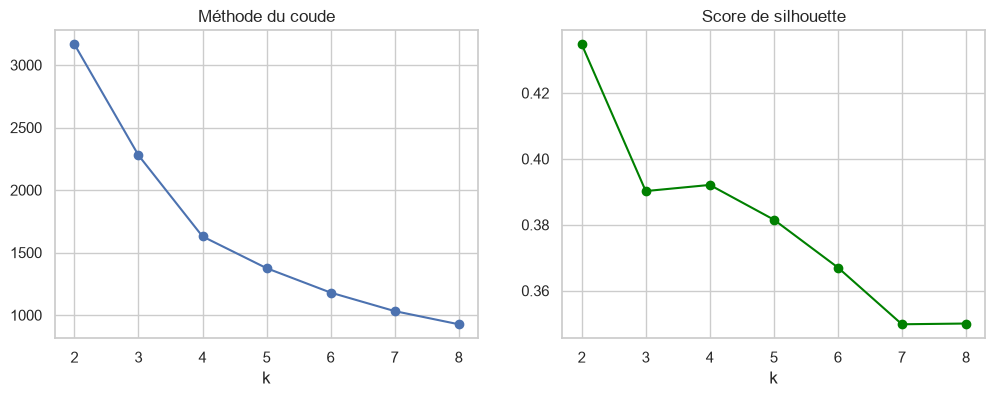

2    0.435
3    0.390
4    0.392
5    0.382
6    0.367
7    0.350
8    0.350
dtype: float64


In [6]:
inertias, sil = [], []
ks = range(2, 9)

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker="o")
ax[0].set_title("Méthode du coude")
ax[0].set_xlabel("k")
ax[1].plot(ks, sil, marker="o", color="green")
ax[1].set_title("Score de silhouette")
ax[1].set_xlabel("k")
plt.show()

print(pd.Series(sil, index=ks).round(3))

In [7]:
K = 4

km = KMeans(n_clusters=K, n_init=10, random_state=42)
df["Cluster"] = km.fit_predict(X)
rfm["Cluster"] = df["Cluster"]

print(df["Cluster"].value_counts().sort_index())

Cluster
0    576
1    478
2    566
3    431
Name: count, dtype: int64


In [8]:
profil = rfm.groupby("Cluster").agg(
    Clients=("Monetary", "count"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
).round(1)

profil["Part_clients_%"] = (profil["Clients"] / profil["Clients"].sum() * 100).round(1)
profil["Part_CA_%"] = (rfm.groupby("Cluster")["Monetary"].sum() / rfm["Monetary"].sum() * 100).round(1)

print(profil.sort_values("Monetary", ascending=False))

         Clients  Recency  Frequency  Monetary  Part_clients_%  Part_CA_%
Cluster                                                                  
3            431     22.7       19.8    1188.3            21.0       41.1
1            478     73.4       19.2    1175.2            23.3       45.1
2            566     23.6        7.1     154.4            27.6        7.0
0            576     73.4        7.0     145.4            28.1        6.7


In [9]:
df["Response_pct"] = df["Response"] * 100

demo = df.groupby("Cluster").agg(
    Age=("Age", "mean"),
    Income=("Income", "mean"),
    Children=("Children", "mean"),
    NbDeals=("NumDealsPurchases", "mean"),
    WebVisits=("NumWebVisitsMonth", "mean"),
    Taux_reponse_pct=("Response_pct", "mean"),
    TotalAccepted=("TotalAccepted", "mean"),
).round(1)

print(demo)

          Age   Income  Children  NbDeals  WebVisits  Taux_reponse_pct  \
Cluster                                                                  
0        43.9  38115.8       1.3      2.4        6.3               4.3   
1        48.0  69022.2       0.6      2.4        4.0              15.3   
2        43.1  37953.7       1.2      2.3        6.3              15.4   
3        46.3  70380.5       0.6      2.3        4.1              29.2   

         TotalAccepted  
Cluster                 
0                  0.1  
1                  0.7  
2                  0.3  
3                  0.9  


         MntWines  MntFruits  MntMeatProducts  MntFishProducts  \
Cluster                                                          
0            68.0        7.0             33.0             10.0   
1           597.0       49.0            331.0             71.0   
2            77.0        7.0             33.0             10.0   
3           594.0       53.0            344.0             73.0   

         MntSweetProducts  MntGoldProds  
Cluster                                  
0                     7.0          20.0  
1                    54.0          73.0  
2                     6.0          22.0  
3                    53.0          72.0  


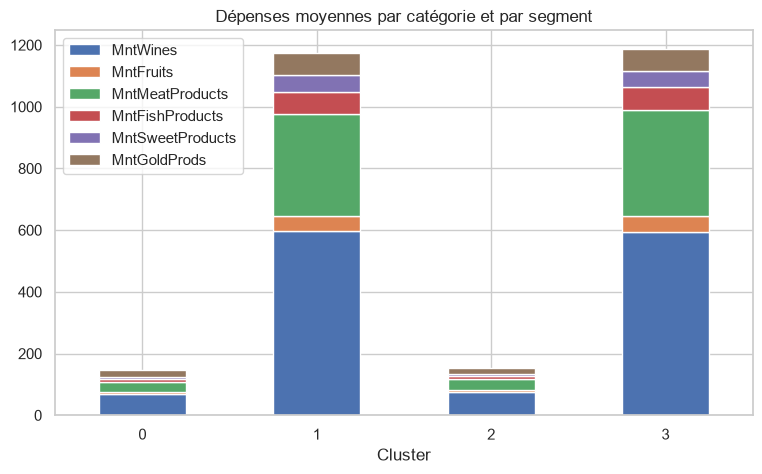

In [10]:
mnt_cols = [c for c in df.columns if c.startswith("Mnt")]
print(df.groupby("Cluster")[mnt_cols].mean().round(0))

df.groupby("Cluster")[mnt_cols].mean().plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Dépenses moyennes par catégorie et par segment")
plt.xticks(rotation=0)
plt.show()

In [15]:
profil = rfm.groupby("Cluster").agg(
    Clients=("Monetary", "count"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
).round(1)
profil["Part_clients_%"] = (profil["Clients"] / profil["Clients"].sum() * 100).round(1)
profil["Part_CA_%"] = (rfm.groupby("Cluster")["Monetary"].sum() / rfm["Monetary"].sum() * 100).round(1)

df["Response_pct"] = df["Response"] * 100
demo = df.groupby("Cluster").agg(
    Age=("Age", "mean"),
    Income=("Income", "mean"),
    Children=("Children", "mean"),
    Taux_reponse_pct=("Response_pct", "mean"),
).round(1)

print(profil.sort_values("Monetary", ascending=False))
print()
print(demo)

         Clients  Recency  Frequency  Monetary  Part_clients_%  Part_CA_%
Cluster                                                                  
3            431     22.7       19.8    1188.3            21.0       41.1
1            478     73.4       19.2    1175.2            23.3       45.1
2            566     23.6        7.1     154.4            27.6        7.0
0            576     73.4        7.0     145.4            28.1        6.7

          Age   Income  Children  Taux_reponse_pct
Cluster                                           
0        43.9  38115.8       1.3               4.3
1        48.0  69022.2       0.6              15.3
2        43.1  37953.7       1.2              15.4
3        46.3  70380.5       0.6              29.2


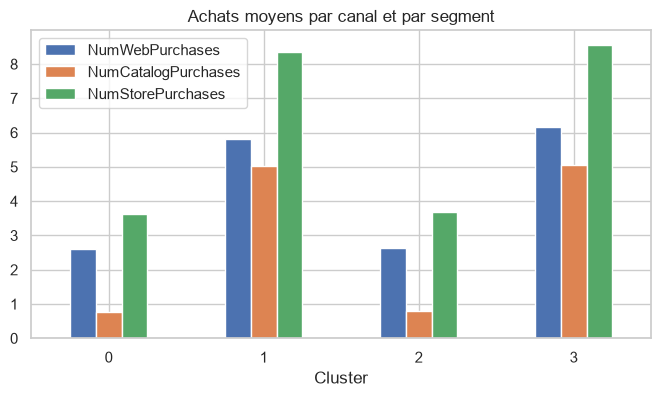

In [11]:
canaux = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
df.groupby("Cluster")[canaux].mean().plot(kind="bar", figsize=(8, 4))
plt.title("Achats moyens par canal et par segment")
plt.xticks(rotation=0)
plt.show()

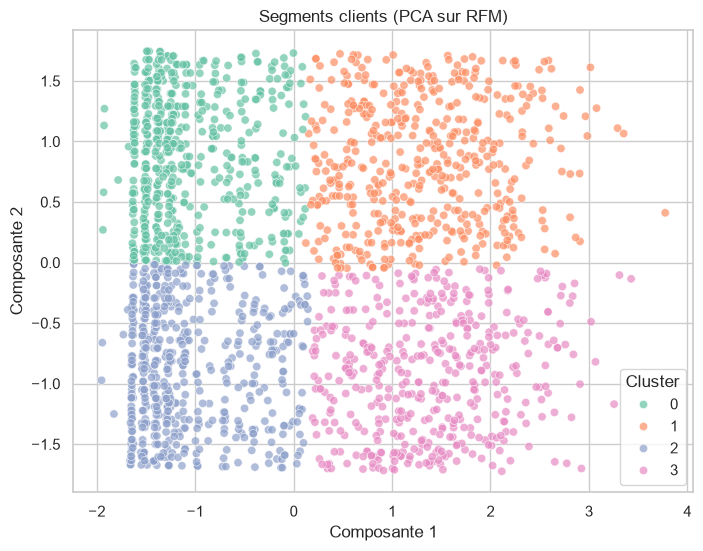

In [12]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["Cluster"],
                palette="Set2", alpha=0.7)
plt.title("Segments clients (PCA sur RFM)")
plt.xlabel("Composante 1")
plt.ylabel("Composante 2")
plt.show()

In [13]:
noms = {
    0: "À définir",
    1: "À définir",
    2: "À définir",
    3: "À définir",
}

df["Segment"] = df["Cluster"].map(noms)
print(df["Segment"].value_counts())

Segment
À définir    2051
Name: count, dtype: int64


In [20]:
gros = profil["Monetary"] >= profil["Monetary"].median()

noms = {}
for est_gros, (n_recent, n_ancien) in {
    True:  ("Premium actifs", "Gros clients à relancer"),
    False: ("Petits clients actifs", "Clients à risque"),
}.items():
    sous = profil[gros == est_gros]
    noms[sous["Recency"].idxmin()] = n_recent
    noms[sous["Recency"].idxmax()] = n_ancien

df["Segment"] = df["Cluster"].map(noms)
print(noms)

resume = df.groupby("Segment").agg(
    Clients=("ID", "count"),
    Depense_moy=("TotalSpent", "mean"),
    Recency=("Recency", "mean"),
    Taux_reponse=("Response", "mean"),
).round(2)
print(resume)

{np.int32(3): 'Premium actifs', np.int32(1): 'Gros clients à relancer', np.int32(2): 'Petits clients actifs', np.int32(0): 'Clients à risque'}
                         Clients  Depense_moy  Recency  Taux_reponse
Segment                                                             
Clients à risque             576       145.44    73.39          0.04
Gros clients à relancer      478      1175.16    73.38          0.15
Petits clients actifs        566       154.42    23.61          0.15
Premium actifs               431      1188.34    22.74          0.29


In [21]:
df.to_csv("../data/marketing_segmented.csv", index=False)

## Conclusions de l'étape 4

- **Méthode** : segmentation RFM standardisée puis K-Means avec K = 4 (coude à k = 4, silhouette = 0,392).
- **Segment le plus rentable** : cluster 3, soit 21.0 % des clients pour 41.1 % du chiffre d'affaires (dépense moyenne 1188, 19.8 achats, revenu moyen 70381).
- **Segment le plus réceptif** : cluster 3, avec un taux de réponse de 29.2 %.
- **Segment à risque** : cluster 0, faibles dépenses (145 en moyenne) et récence élevée (73 jours).
- **Lecture globale** : deux segments à fortes dépenses (vins et viande dominants) et deux à faibles dépenses, séparés ensuite selon la récence.
- **Limites** : la récence est peu corrélée aux dépenses, la segmentation repose surtout sur la fréquence et le montant.


## Segments retenus

| Segment | Clients | Dépense moyenne | Récence (jours) | Taux de réponse |
|---|---|---|---|---|
| Premium actifs | 431 | 1 188 | 23 | 29 % |
| Gros clients à relancer | 478 | 1 175 | 73 | 15 % |
| Petits clients actifs | 566 | 154 | 24 | 15 % |
| Clients à risque | 576 | 145 | 73 | 4 % |

## Insights

- Les deux segments à fortes dépenses représentent environ 86 % du chiffre d'affaires.
- À niveau de dépenses égal, la récence change fortement la réponse aux campagnes : 29 % contre 15 % chez les gros clients, 15 % contre 4 % chez les petits.
- Les « gros clients à relancer » pèsent environ 45 % du chiffre d'affaires mais n'ont rien acheté depuis 73 jours en moyenne : c'est le principal risque et la principale opportunité.

## Recommandations

- **Premium actifs** : programme de fidélité et offres exclusives (vins, viande), segment le plus réceptif.
- **Gros clients à relancer** : campagne de réactivation prioritaire avant qu'ils ne partent.
- **Petits clients actifs** : promotions pour augmenter la fréquence et le panier.
- **Clients à risque** : ne pas investir en campagnes coûteuses (4 % de réponse), privilégier un canal peu cher.